<a href="https://colab.research.google.com/github/costpetrides/Numerical-Methods-GFD/blob/main/Petrides/Solutions/Derivative/Derivative.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Άσκηση 1.1



\begin{equation}
\boxed{
\left.\frac{du}{dx}\right|_{x_i}
\simeq
\frac{u_{i+1}-u_i}{h}
\qquad \mathcal{O}(h)
} \rightarrow forward
\end{equation}

\begin{equation}
\boxed{
\left.\frac{du}{dx}\right|_{x_i}
\simeq
\frac{u_i-u_{i-1}}{h}
\qquad \mathcal{O}(h)
} \rightarrow backward
\end{equation}


\begin{equation}
\boxed{
\left.\frac{du}{dx}\right|_{x_i}
\simeq
\frac{u_{i+1}-u_{i-1}}{2h}
\qquad \mathcal{O}(h^2)
} \rightarrow centered
\end{equation}

In [ ]:
# (α)

def du(h):
  x=np.arange(0,2+h,h)
  u= np.exp(x)*np.sin(x)

  # Forward
  i= round(1 / h)
  du_f= (u[i+1]-u[i])/h

  # Backward
  du_b= (u[i]-u[i-1])/h

  # centered
  du_c = (u[i+1] - u[i-1]) / (2*h)
  return du_f, du_b, du_c

for h in [0.2, 0.1, 0.05, 0.025]:
    du_f, du_b, du_c = du(h)

    print(f"\nFor h = {h}")
    print(f"Forward Difference:  {du_f:.2f}")
    print(f"Backward Difference: {du_b:.2f}")
    print(f"Centered Difference: {du_c:.2f}")


For h = 0.2
Forward Difference:  4.04
Backward Difference: 3.45
Centered Difference: 3.74

For h = 0.1
Forward Difference:  3.90
Backward Difference: 3.61
Centered Difference: 3.75

For h = 0.05
Forward Difference:  3.83
Backward Difference: 3.68
Centered Difference: 3.76

For h = 0.025
Forward Difference:  3.79
Backward Difference: 3.72
Centered Difference: 3.76



\begin{aligned}
E_F &= |D_F-f'(1)|,\\
E_B &= |D_B-f'(1)|,\\
E_C &= |D_C-f'(1)|.
\end{aligned}

In [ ]:
# (β)

df_1=np.exp(1)*(np.sin(1)+np.cos(1))

Df1 , Db1, Dc1 =du(0.1)
Df2 , Db2, Dc2 =du(0.2)

def ET(h):
    return np.abs(np.array(du(h)) - df_1)




print("\nh=0.1")
print(f"Eforward: {ET(0.1)[0]:.6f}")
print(f"Ebackward: {ET(0.1)[1]:.6f}")
print(f"Ecentered: {ET(0.1)[2]:.6f}")

print("\nh=0.2")
print(f"Eforward: {ET(0.2)[0]:.6f}")
print(f"Ebackward: {ET(0.2)[1]:.6f}")
print(f"Ecentered: {ET(0.2)[2]:.6f}")


h=0.1
Eforward: 0.143747
Ebackward: 0.149229
Ecentered: 0.002741

h=0.2
Eforward: 0.279568
Ebackward: 0.301799
Ecentered: 0.011116


Παρατηρούμε ότι για το  Forward και Backward Difference,  όταν υποδιπλασιάζουμε το βήμα από \(h=0.2\) σε \(h=0.1\), το σφάλμα μειώνεται περίπου στο μισό. Ενώ για την Centered  το σφάλμα μειώνεται περίπου στο ένα τέταρτο!


In [ ]:
# (γ)

print("\nΤάξη σύγκλισης για κάθε μέθοδο")
print(f"Forward  p = {np.log2(ET(0.2)[0]/ET(0.1)[0]):.6f}")
print(f"Backward p = {np.log2(ET(0.2)[1]/ET(0.1)[1]):.6f}")
print(f"Centered  p = {np.log2(ET(0.2)[2]/ET(0.1)[2]):.6f}")


Τάξη σύγκλισης για κάθε μέθοδο
Forward  p = 0.959671
Backward p = 1.016059
Centered  p = 2.019622


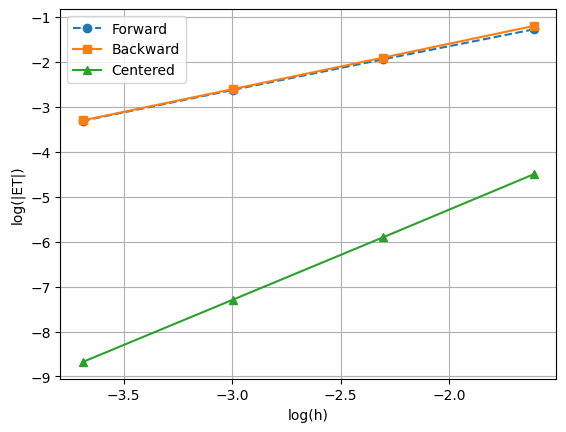

In [ ]:
h = np.array([0.2, 0.1, 0.05, 0.025])

EF = np.array([ET(hi)[0] for hi in h])
EB = np.array([ET(hi)[1] for hi in h])
EC = np.array([ET(hi)[2] for hi in h])

plt.plot(np.log(h), np.log(EF), "o--" ,label="Forward")
plt.plot(np.log(h), np.log(EB), "s-", label="Backward")
plt.plot(np.log(h), np.log(EC), "^-",  label="Centered")

plt.legend()
plt.xlabel("log(h)")
plt.ylabel("log(|ET|)")
plt.grid(True)
plt.show()

# Άσκηση 1.2




\begin{equation}
\boxed{
\left.\frac{d^2u}{dx^2}\right|_{x_i}
\simeq
\frac{u_{i-1}-2u_i+u_{i+1}}{h^2}
\qquad \mathcal{O}(h^2)
} → centered
\end{equation}

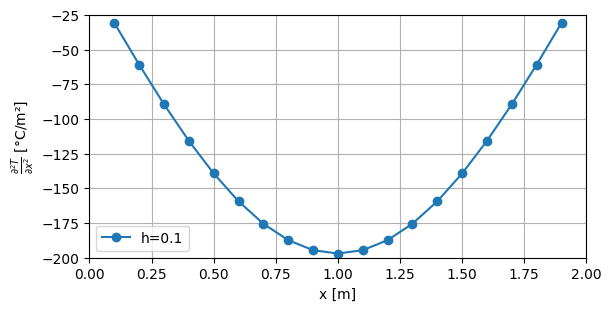

In [ ]:
# (α)

h = 0.1
L = 2  # m

x = np.arange(0, L+h, h)
T = 20 + 80*np.sin(np.pi*x/L)

# Centered Difference - Second derivative
i = np.arange(1, len(T)-1)
dT2 = (T[i-1] - 2*T[i] + T[i+1]) / h**2

plt.figure(figsize=(6, 3), layout="constrained")
plt.plot(x[i], dT2, "o-", label="h=0.1")
plt.grid(True)
plt.legend()
plt.xlabel("x [m]")
plt.ylabel(r"$\frac{\partial^2 T}{\partial x^2}$ [°C/m²]")
plt.xlim(0, 2)
plt.ylim(-200,-25)
plt.show()

\begin{equation}
\frac{\partial T}{\partial t}
=
\alpha\frac{\partial^2T}{\partial x^2}
\end{equation}

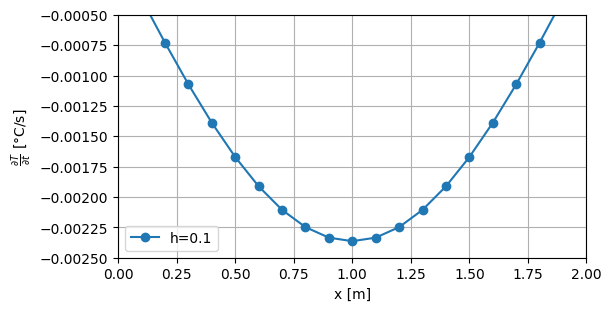

Η θερμοκρασία μειώνεται με ρυθμό -0.002364 °C/s στο x = 1.00 m


In [ ]:
# (β)
a = 1.2e-5  # m²/s
dT=a* dT2

plt.figure(figsize=(6, 3), layout="constrained")
plt.plot(x[i], dT, "o-", label="h=0.1")
plt.grid(True)
plt.legend()
plt.xlabel("x [m]")
plt.ylabel(r"$\frac{\partial T}{\partial t}$ [°C/s]")
plt.xlim(0, 2)
plt.ylim(-0.0025,-0.0005)
plt.show()

j = np.argmin(dT)
print(f"Η θερμοκρασία μειώνεται με ρυθμό {np.min(dT):.6f} °C/s στο x = {x[i[j]]:.2f} m")

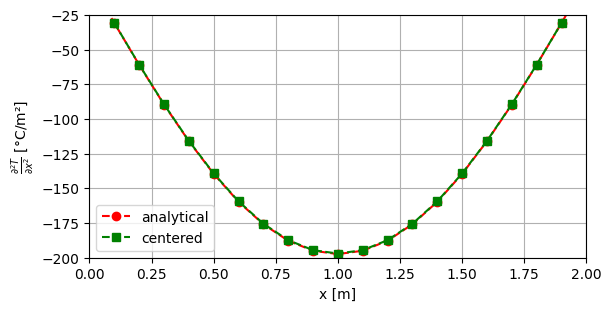

In [ ]:
# (γ)
x = np.arange(0, L+h, h)

dT2_anal=-(80 * np.pi**2 * np.sin((np.pi * x) / L)) / (L**2)


plt.figure(figsize=(6, 3), layout="constrained")
plt.plot(x,dT2_anal, "o--", c='r', label="analytical")
plt.plot(x[i], dT2, "s--", c='g', label="centered")
plt.grid(True)
plt.legend()
plt.xlabel("x [m]")
plt.ylabel(r"$\frac{\partial^2 T}{\partial x^2}$ [°C/m²]")
plt.xlim(0, 2)
plt.ylim(-200,-25)
plt.show()


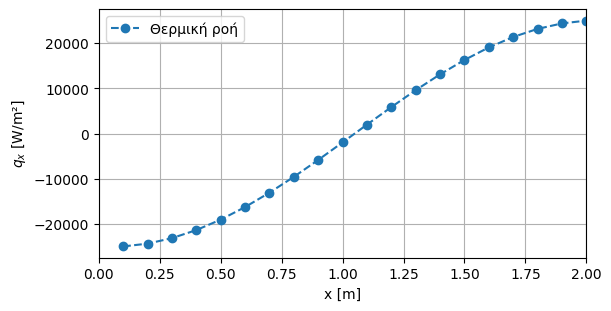

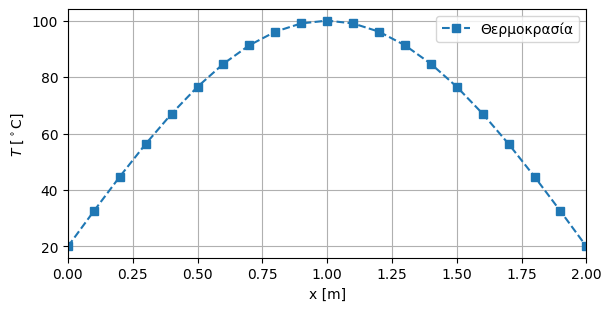

In [ ]:
# (δ)

h = 0.1
L = 2  # m
k = 200  # W/(m K)

x = np.arange(0, L+h, h)
T = 20 + 80*np.sin(np.pi*x/L)

i = np.arange(1, len(T))
dT_b = (T[i] - T[i-1]) / h

q = -k*dT_b

# Θερμική ροή
plt.figure(figsize=(6, 3), layout="constrained")
plt.plot(x[i], q, "o--", label="Θερμική ροή")
plt.grid(True)
plt.legend()
plt.xlabel("x [m]")
plt.ylabel(r"$q_x$ [W/m²]")
plt.xlim(0, 2)
plt.show()

# Θερμοκρασία
plt.figure(figsize=(6, 3), layout="constrained")
plt.plot(x, T, "s--", label="Θερμοκρασία")
plt.grid(True)
plt.legend()
plt.xlabel("x [m]")
plt.ylabel(r"$T$ [$^\circ$C]")
plt.xlim(0, 2)
plt.show()

h = 0.20 m, Max Error = 1.618153
h = 0.10 m, Max Error = 0.405538
h = 0.05 m, Max Error = 0.101447


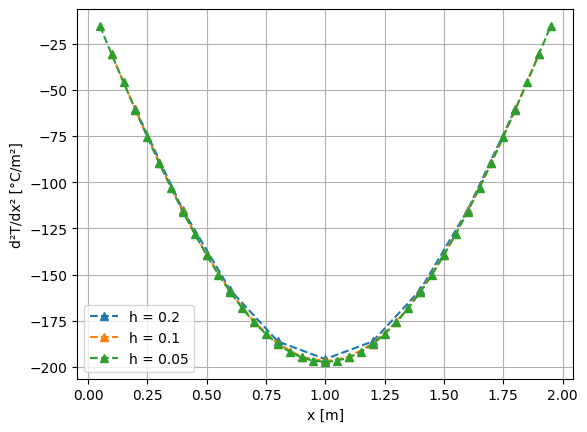

In [ ]:

L = 2  # m

for h in [0.2, 0.1, 0.05]:

    x = np.arange(0, L+h, h)
    T = 20 + 80*np.sin(np.pi*x/L)

    # Central Difference - Second Derivative
    i = np.arange(1, len(T)-1)
    d2T = (T[i-1] - 2*T[i] + T[i+1]) / h**2

    # Analytical Second Derivative
    exact = -80*(np.pi/L)**2 * np.sin(np.pi*x[i]/L)

    # Maximum Absolute Error
    error = np.max(np.abs(d2T - exact))

    print(f"h = {h:.2f} m, Max Error = {error:.6f}")

    plt.plot(x[i], d2T, "^--", label=f"h = {h}")

plt.xlabel("x [m]")
plt.ylabel("d²T/dx² [°C/m²]")
plt.legend()
plt.grid(True)
plt.show()